In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import cross_val_predict, RandomizedSearchCV
from sklearn.ensemble import VotingClassifier
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
import xgboost as xgb
from catboost import CatBoostClassifier

In [2]:
data_train = pd.read_csv(Path('data/fashion-mnist_test.csv'))
data_test = pd.read_csv(Path('data/fashion-mnist_train.csv'))

## Data analysis

In [3]:
data_train.head(10)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,2,0,0,0,0,0,44,105,44,10,...,105,64,30,0,0,0,0,0,0,0
6,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,6,0,0,0,0,0,0,0,1,0,...,174,136,155,31,0,1,0,0,0,0
8,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,57,70,28,0,2,0,0,0,0,0


In [4]:
y_train = data_train['label'].copy()
data_train.drop('label', axis=1, inplace=True)

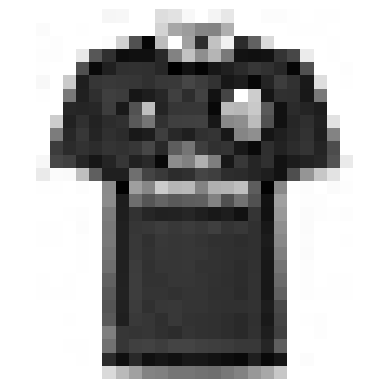

In [12]:
def plot_fashion(data):
    image = data.values.reshape(28, 28)
    plt.imshow(image, cmap='binary')
    plt.axis('off')

exemplary_fashion = data_train.iloc[0, 0:]
plot_fashion(exemplary_fashion)
plt.show()

In [14]:
y_train[0]

np.int64(0)

Images in this dataset are divided into 10 different labels. Each is represented as follows:
1. T-shirt/top
2. Trouser
3. Pullover
4. Dress
5. Coat
6. Sandal
7. Shirt
8. Sneaker
9. Bag
10. Ankle boot